In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("imakash3011/online-shoppers-purchasing-intention-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'online-shoppers-purchasing-intention-dataset' dataset.
Path to dataset files: /kaggle/input/online-shoppers-purchasing-intention-dataset


In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv(path + '/online_shoppers_intention.csv')

In [ ]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Загрузка данных

In [ ]:
df.shape

(12330, 18)

In [ ]:
df.columns

Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='object')

In [ ]:
print('Все колонки:', df.columns.tolist())
df.info()

Все колонки: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  

## 2. EDA (Exploratory Data Analysis)

In [ ]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:
df.describe().round(2)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00,12330.00
mean,2.32,80.82,0.50,34.47,31.73,1194.75,0.02,0.04,5.89,0.06,2.12,2.36,3.15,4.07
std,3.32,176.78,1.27,140.75,44.48,1913.67,0.05,0.05,18.57,0.20,0.91,1.72,2.40,4.03
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00
25%,0.00,0.00,0.00,0.00,7.00,184.14,0.00,0.01,0.00,0.00,2.00,2.00,1.00,2.00
50%,1.00,7.50,0.00,0.00,18.00,598.94,0.00,0.03,0.00,0.00,2.00,2.00,3.00,2.00
75%,4.00,93.26,0.00,0.00,38.00,1464.16,0.02,0.05,0.00,0.00,3.00,2.00,4.00,4.00
max,27.00,3398.75,24.00,2549.38,705.00,63973.52,0.20,0.20,361.76,1.00,8.00,13.00,9.00,20.00


In [ ]:
df.isnull().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [ ]:
df.VisitorType.value_counts()

,count
VisitorType,
Returning_Visitor,10551
New_Visitor,1694
Other,85


In [ ]:
df.SpecialDay.value_counts()

,count
SpecialDay,
0.0,11079
0.6,351
0.8,325
0.4,243
0.2,178
1.0,154


In [ ]:
df.Month.value_counts(), len(df.Month.value_counts())

(Month
 May     3364
 Nov     2998
 Mar     1907
 Dec     1727
 Oct      549
 Sep      448
 Aug      433
 Jul      432
 June     288
 Feb      184
 Name: count, dtype: int64,
 10)

### Распределение классов (целевая переменная $Y$)

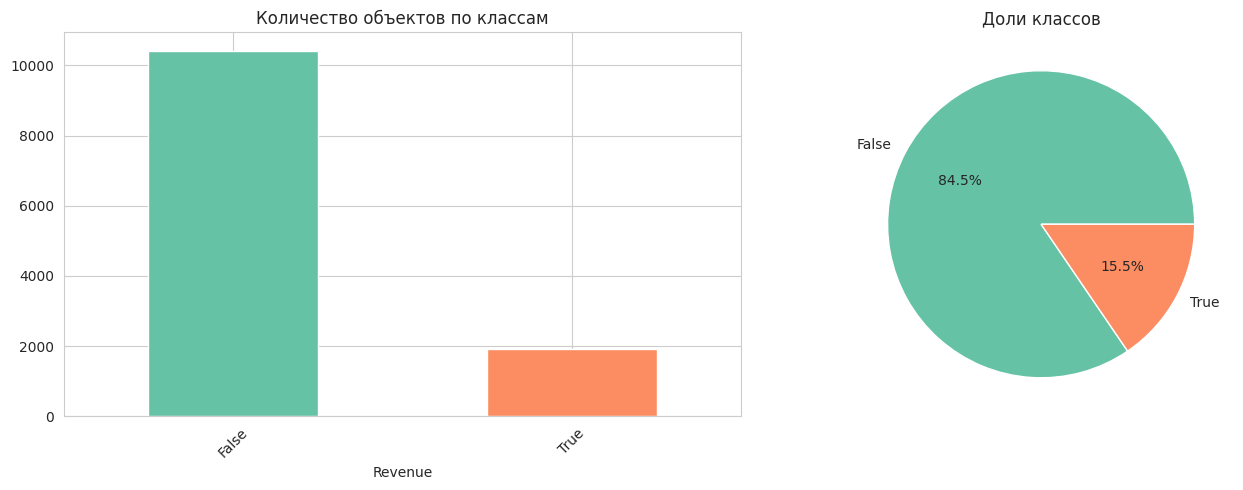

In [ ]:
target_col = 'Revenue'
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df[target_col].value_counts().plot.bar(ax=axes[0], color=sns.color_palette('Set2'))
axes[0].set_title('Количество объектов по классам')
axes[0].tick_params(axis='x', rotation=45)

df[target_col].value_counts(normalize=True).plot.pie(ax=axes[1], autopct='%1.1f%%', colors=sns.color_palette('Set2'))
axes[1].set_ylabel('')
axes[1].set_title('Доли классов')
plt.tight_layout()
plt.show()

### Распределения признаков $x_1, x_2, \ldots, x_d$

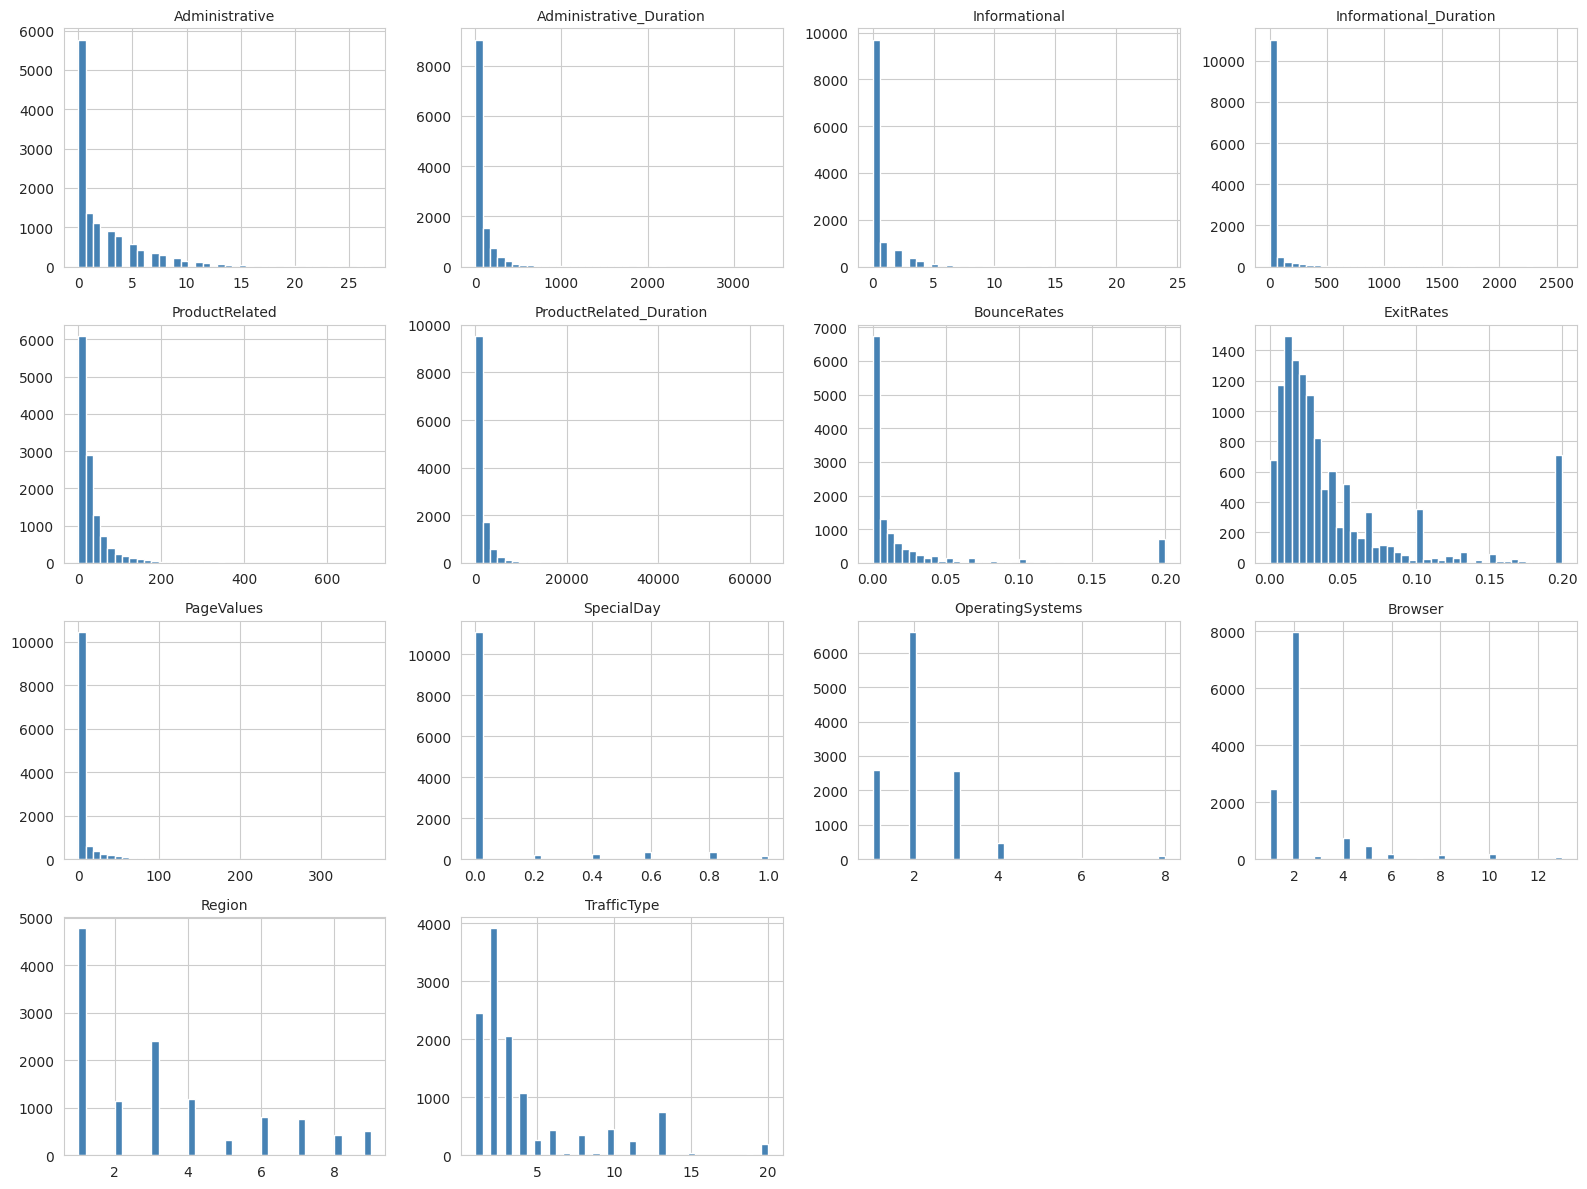

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

n_cols = len(numeric_cols)
n_rows = (n_cols + 3) // 4
fig, axes = plt.subplots(n_rows, 4, figsize=(16, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    df[col].hist(bins=40, ax=axes[i], color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=10)

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

### Корреляционная матрица

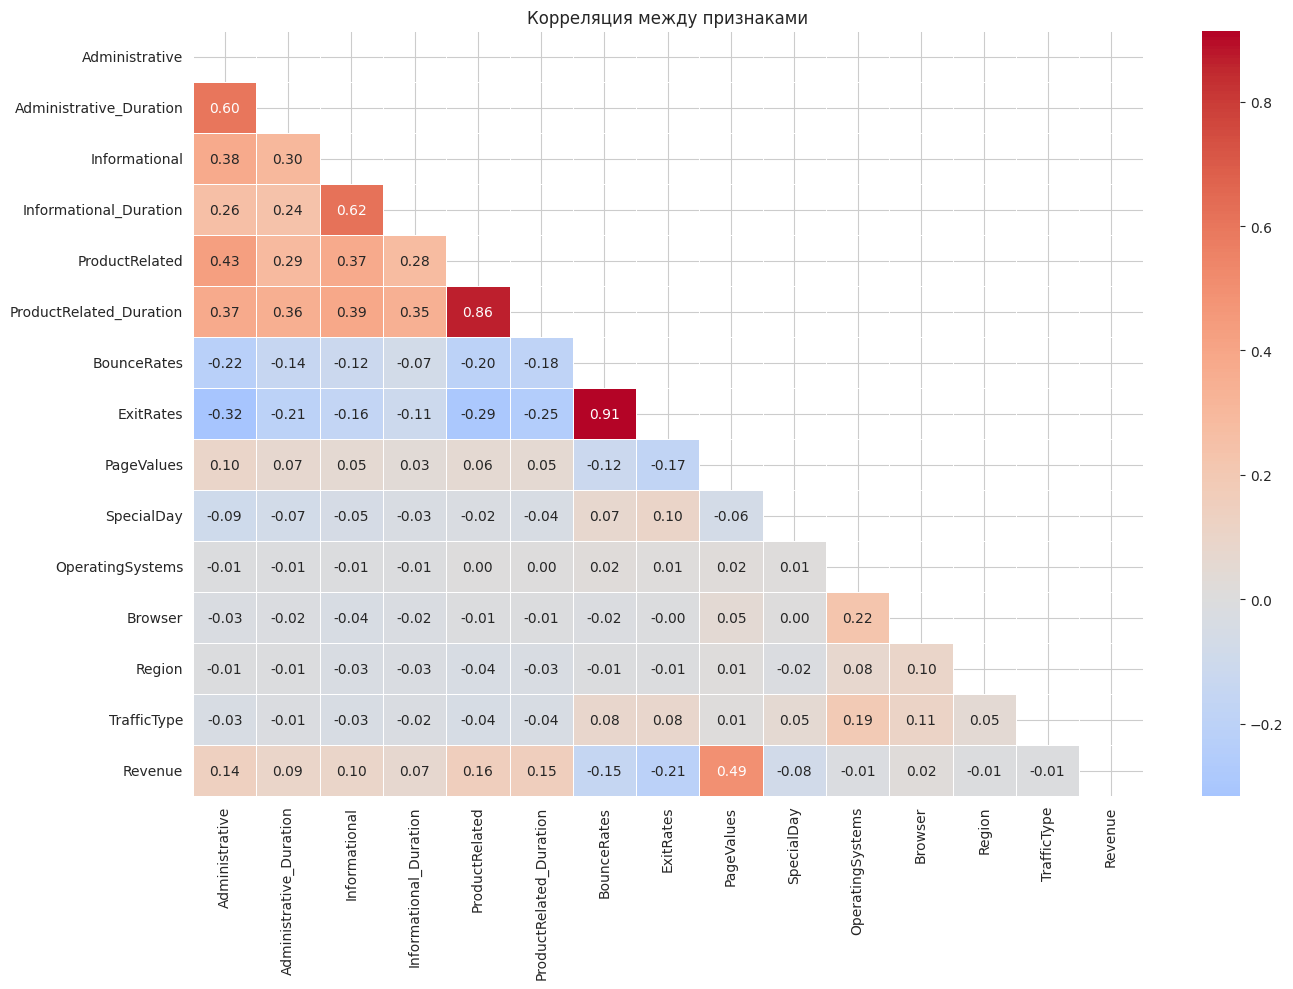

In [ ]:
plt.figure(figsize=(14, 10))
corr = df[numeric_cols + [target_col]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Корреляция между признаками')
plt.tight_layout()
plt.show()

In [ ]:
corr[target_col].drop(target_col).sort_values(key=abs, ascending=False).round(2).head(11).to_frame('corr Revenue')

,corr Revenue
PageValues,0.49
ExitRates,-0.21
ProductRelated,0.16
ProductRelated_Duration,0.15
BounceRates,-0.15
Administrative,0.14
Informational,0.10
Administrative_Duration,0.09
SpecialDay,-0.08
Informational_Duration,0.07


### Boxplot признаков по классам

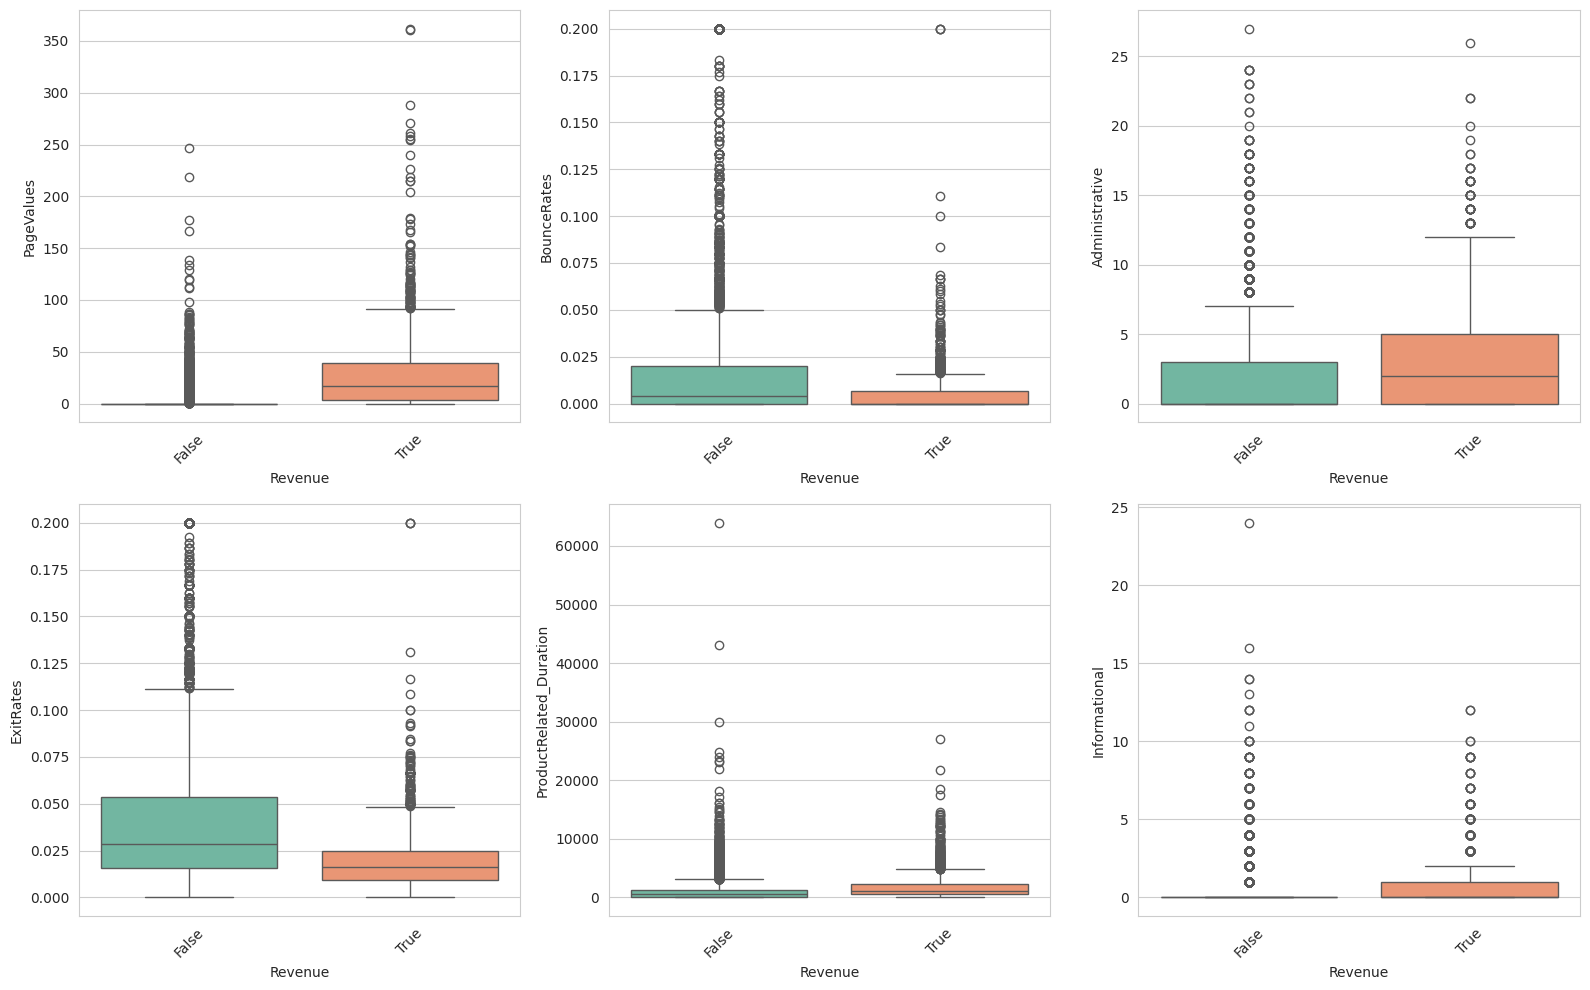

In [ ]:
main = ['PageValues', 'ExitRates', 'BounceRates', 'ProductRelated_Duration', 'Administrative', 'Informational']
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for idx, col in enumerate(main):
    ax = axes[idx % 2][idx // 2]
    sns.boxplot(data=df, x=target_col, y=col, ax=ax, palette='Set2')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
g = df.groupby(df['PageValues'] > 0)[target_col].agg(['mean', 'size'])
g.index = ['PageValues = 0', 'PageValues > 0']
g

,mean,size
PageValues = 0,0.038542,9600
PageValues > 0,0.563370,2730


### Pairplot (ключевые признаки)

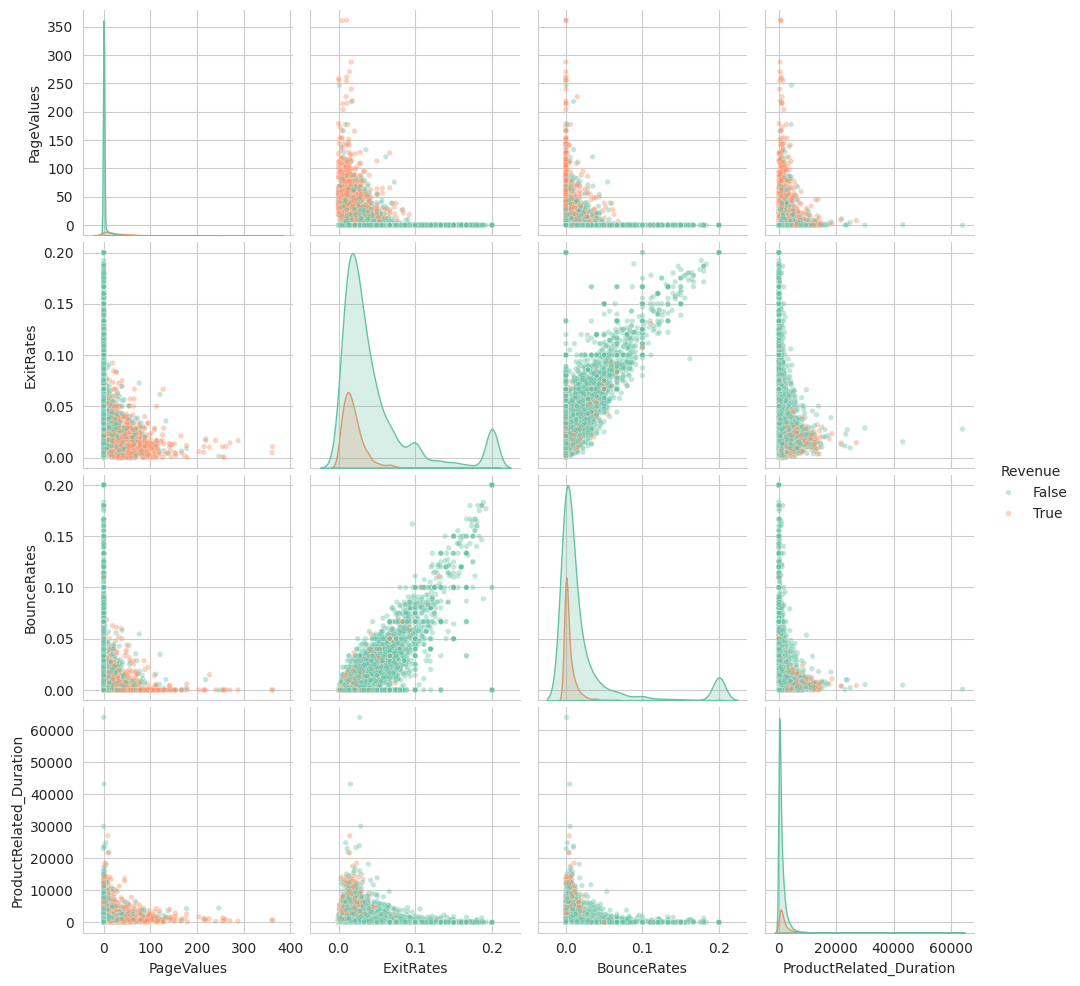

In [ ]:
sns.pairplot(df[['PageValues', 'ExitRates', 'BounceRates', 'ProductRelated_Duration'] + [target_col]],
             hue=target_col, palette='Set2', plot_kws={'alpha': 0.4, 's': 15})
plt.show()

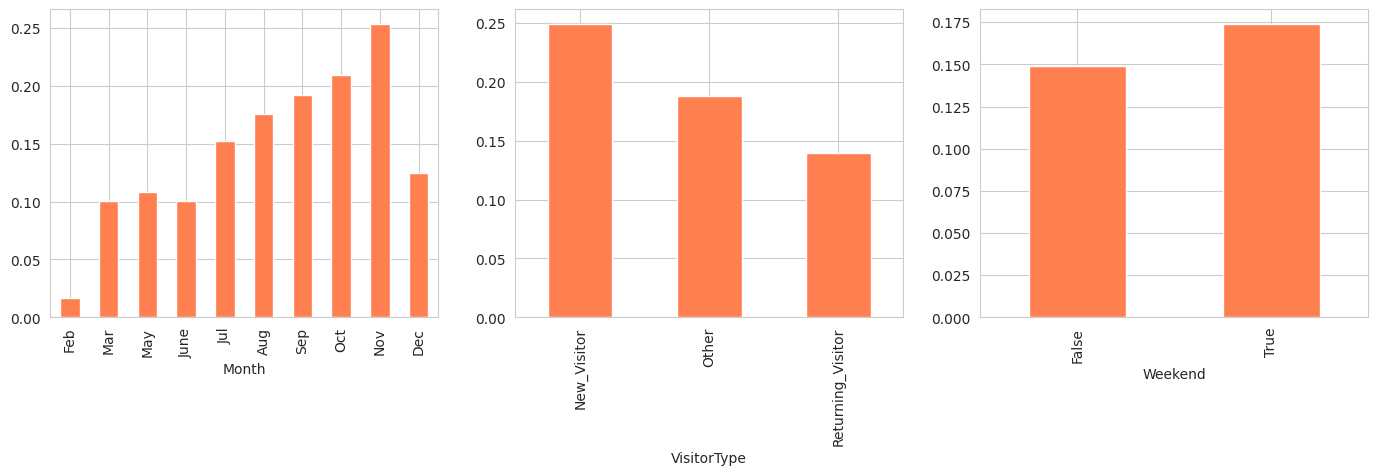

In [ ]:
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
df.groupby('Month')['Revenue'].mean().reindex(month_order).plot.bar(ax=axes[0], color='coral')
df.groupby('VisitorType')['Revenue'].mean().plot.bar(ax=axes[1], color='coral')
df.groupby('Weekend')['Revenue'].mean().plot.bar(ax=axes[2], color='coral')
plt.show()

## 3. Подготовка данных


In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
df['Weekend'] = df['Weekend'].astype(int)

y = df['Revenue'].astype(int)
X = df.drop(columns='Revenue')

In [ ]:
log_cols = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
            'ProductRelated', 'ProductRelated_Duration', 'PageValues']
cat_cols = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

X[log_cols] = np.log1p(X[log_cols])
X = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)

In [ ]:
X.shape

(12205, 68)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

In [ ]:
X_train.shape, X_test.shape

((9764, 68), (2441, 68))

In [ ]:
pd.Series({'train': y_train.mean(), 'test': y_test.mean()}, name='доля покупок')

,доля покупок
train,0.156288
test,0.156493


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True)

## 4. Метрики и baseline
Baseline: Dummy (всегда "нет покупки"), логистическая регрессия и дерево с параметрами по умолчанию.

In [ ]:
baseline_models = {
    'Dummy (всегда 0)': DummyClassifier(strategy='most_frequent'),
    'LogReg': Pipeline([('scaler', StandardScaler()),
                        ('LogisticRegression', LogisticRegression(max_iter=1000))]),
    'DecisionTree (default)': DecisionTreeClassifier(),
}
metrics = ['accuracy', 'f1_macro', 'f1', 'roc_auc']

baseline_rows = []
for name, model in baseline_models.items():
    row = {'Model': name}
    for m in metrics:
        row[m] = cross_val_score(model, X_train, y_train, cv=cv, scoring=m).mean()
    baseline_rows.append(row)

In [ ]:
pd.DataFrame(baseline_rows).set_index('Model')

,accuracy,f1_macro,f1,roc_auc
Model,,,,
Dummy (всегда 0),0.843712,0.457616,0.000000,0.500000
LogReg,0.894716,0.776584,0.621040,0.912372
DecisionTree (default),0.863580,0.752774,0.565353,0.740247


**Вывод:** у Dummy accuracy 0.844 при F1 = 0 - то есть высокая accuracy сама по себе ничего не значит. Логистическая регрессия даёт accuracy 0.893, но F1 по классу "покупка" всего 0.616. Дерево без ограничений глубины сильно переобучено (ROC-AUC 0.747 против 0.909 у LogReg), поэтому глубину дерева нужно подбирать.

## 5. Подбор гиперпараметров

Критерий подбора - ROC-AUC (`scoring='roc_auc'`). Для логистической регрессии и дерева используем `GridSearchCV`, для Random Forest - `RandomizedSearchCV` (пространство больше).

In [ ]:
from scipy.stats import randint
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif, RFE
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

In [ ]:
pipe_lr = Pipeline([('scaler', StandardScaler()),
                    ('LogisticRegression', LogisticRegression(max_iter=1000))])

grid_lr = GridSearchCV(pipe_lr, {'LogisticRegression__C': [0.001, 0.01, 0.1, 1, 10, 100]},
                       cv=cv, scoring='roc_auc')
grid_lr.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('LogisticRegression',
                                        LogisticRegression(max_iter=1000))]),
             param_grid={'LogisticRegression__C': [0.001, 0.01, 0.1, 1, 10,
                                                   100]},
             scoring='roc_auc')

In [ ]:
param_grid = {
    'max_depth': [3, 4, 5, 6, 8, 10, 15, None],
    'min_samples_leaf': [1, 5, 10, 20, 50],
    'criterion': ['gini', 'entropy'],
}

grid_dt = GridSearchCV(DecisionTreeClassifier(), param_grid, cv=cv, scoring='roc_auc')
grid_dt.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=True),
             estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 4, 5, 6, 8, 10, 15, None],
                         'min_samples_leaf': [1, 5, 10, 20, 50]},
             scoring='roc_auc')

In [ ]:
param_dist = {
    'n_estimators': randint(100, 250),
    'max_depth': randint(3, 20),
    'min_samples_leaf': randint(1, 20),
    'max_features': ['sqrt', 0.3, 0.5],
}

rand_rf = RandomizedSearchCV(RandomForestClassifier(), param_dist,
                             n_iter=10, cv=cv, scoring='roc_auc')
rand_rf.fit(X_train, y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=True),
                   estimator=RandomForestClassifier(),
                   param_distributions={'max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7e33ecf47390>,
                                        'max_features': ['sqrt', 0.3, 0.5],
                                        'min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7e33ecf47c50>,
                                        'n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7e33f72b8c20>},
                   scoring='roc_auc')

In [ ]:
searches = {'LogReg': grid_lr, 'DecisionTree': grid_dt, 'RandomForest': rand_rf}

pd.DataFrame({
    'Best CV ROC-AUC': {name: s.best_score_ for name, s in searches.items()},
    'Best params': {name: s.best_params_ for name, s in searches.items()}})

,Best CV ROC-AUC,Best params
LogReg,0.915542,{'LogisticRegression__C': 0.01}
DecisionTree,0.925402,"{'criterion': 'entropy', 'max_depth': 6, 'min_..."
RandomForest,0.933946,"{'max_depth': 19, 'max_features': 0.5, 'min_sa..."


## 6. Сравнение моделей (проверка H1 и H2)

Сравниваем три модели с подобранными параметрами: сначала по кросс-валидации на train, затем один раз на отложенном тесте.

In [ ]:
best_models = {
    'LogReg': grid_lr.best_estimator_,
    'DecisionTree': grid_dt.best_estimator_,
    'RandomForest': rand_rf.best_estimator_,
}

cv_rows = []
for name, model in best_models.items():
    row = {'Model': name}
    for m in ['roc_auc', 'f1']:
        scores = cross_val_score(model, X_train, y_train, cv=cv, scoring=m)
        row['CV ' + m + ' (mean+-std)'] = f'{scores.mean():.3f}+-{scores.std():.3f}'
    cv_rows.append(row)

In [ ]:
pd.DataFrame(cv_rows).set_index('Model')

,CV roc_auc (mean+-std),CV f1 (mean+-std)
Model,,
LogReg,0.916+-0.007,0.604+-0.026
DecisionTree,0.927+-0.006,0.650+-0.025
RandomForest,0.934+-0.003,0.661+-0.023


In [ ]:
test_rows = []
proba_test = {}
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    proba_test[name] = model.predict_proba(X_test)[:, 1]
    test_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'F1 (macro)': f1_score(y_test, y_pred, average='macro'),
        'ROC-AUC': roc_auc_score(y_test, proba_test[name]),
        'PR-AUC': average_precision_score(y_test, proba_test[name]),
    })

In [ ]:
pd.DataFrame(test_rows).set_index('Model').round(3)

,Accuracy,Precision,Recall,F1,F1 (macro),ROC-AUC,PR-AUC
Model,,,,,,,
LogReg,0.888,0.689,0.521,0.593,0.764,0.912,0.663
DecisionTree,0.899,0.718,0.586,0.646,0.793,0.916,0.684
RandomForest,0.902,0.738,0.584,0.652,0.798,0.926,0.736


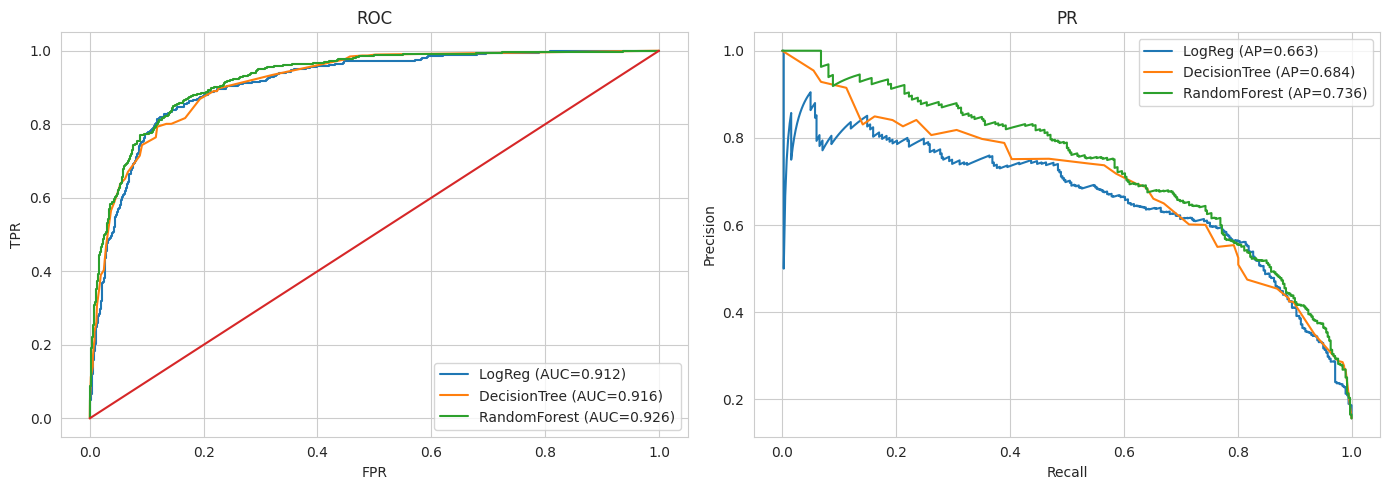

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, proba in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, proba):.3f})')
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f'{name} (AP={average_precision_score(y_test, proba):.3f})')
axes[0].plot([0, 1], [0, 1])
axes[0].set_xlabel('FPR')
axes[0].set_ylabel('TPR')
axes[0].set_title('ROC')
axes[0].legend()
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('PR')
axes[1].legend()
plt.tight_layout()
plt.show()

**H1: не подтвердилась.**
Логистическая регрессия оказалась хуже дерева: ROC-AUC на кросс-валидации 0.912 против 0.924 (std около 0.008), на тесте 0.921 против 0.927. Разница небольшая, но во всех замерах в пользу дерева. Значит, зависимость от признаков не совсем линейная: например, `PageValues = 0` почти всегда означает "нет покупки", а для остальных значений картина другая, и дерево ловит такие пороги лучше. Оговорка: это верно только для дерева с подобранной глубиной, дерево по умолчанию было намного хуже LogReg (0.747).

**H2: подтвердилась частично.**
Random Forest лучше одиночного дерева по обеим метрикам, но разница небольшая. ROC-AUC на CV: 0.932 против 0.924 (на тесте 0.933 против 0.927). F1 на CV: 0.656 против 0.643, но std у дерева 0.045, поэтому по F1 разница находится в пределах шума (на тесте 0.667 против 0.663). Заметный выигрыш Random Forest даёт только по PR-AUC на тесте (0.754 против 0.694). Причина та же, что в гипотезе: усреднение деревьев снижает разброс, но подобранное неглубокое дерево и так переобучено не сильно.

## 7. Переобучение дерева (проверка H3)

Обучаем дерево с разной глубиной. Качество на train сравниваем с качеством на кросс-валидации по train (тест не используем).

In [ ]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30]
depth_rows = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d).fit(X_train, y_train)
    depth_rows.append({
        'max_depth': d,
        'train accuracy': accuracy_score(y_train, dt.predict(X_train)),
        'CV accuracy': cross_val_score(DecisionTreeClassifier(max_depth=d),
                                       X_train, y_train, cv=cv, scoring='accuracy').mean(),
        'train F1': f1_score(y_train, dt.predict(X_train)),
        'CV F1': cross_val_score(DecisionTreeClassifier(max_depth=d),
                                 X_train, y_train, cv=cv, scoring='f1').mean(),
    })
df_depth = pd.DataFrame(depth_rows).set_index('max_depth')

In [ ]:
df_depth.round(3)

,train accuracy,CV accuracy,train F1,CV F1
max_depth,,,,
1,0.875,0.874,0.663,0.661
2,0.889,0.888,0.564,0.560
3,0.898,0.897,0.654,0.631
4,0.905,0.899,0.669,0.640
5,0.911,0.900,0.697,0.628
6,0.914,0.897,0.685,0.630
8,0.935,0.890,0.780,0.618
10,0.955,0.885,0.849,0.601
12,0.975,0.884,0.916,0.577


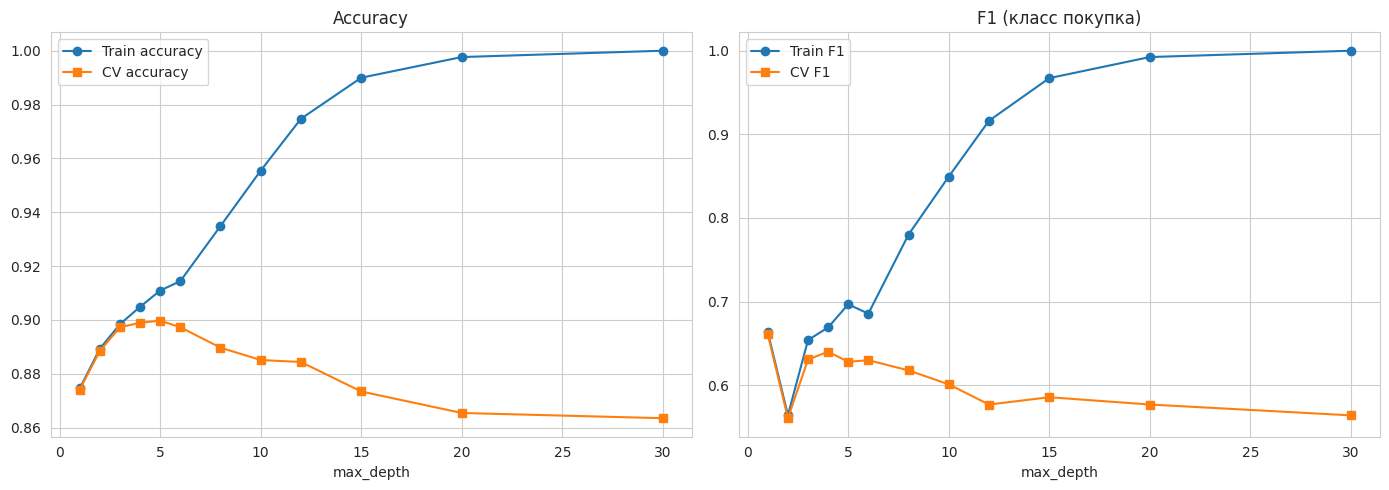

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(df_depth.index, df_depth['train accuracy'], 'o-', label='Train accuracy')
axes[0].plot(df_depth.index, df_depth['CV accuracy'], 's-', label='CV accuracy')
axes[0].set_title('Accuracy')
axes[1].plot(df_depth.index, df_depth['train F1'], 'o-', label='Train F1')
axes[1].plot(df_depth.index, df_depth['CV F1'], 's-', label='CV F1')
axes[1].set_title('F1 (класс покупка)')
for ax in axes:
    ax.set_xlabel('max_depth')
    ax.legend()
plt.tight_layout()
plt.show()

**H3: подтвердилась.**
При глубине 10 train accuracy = 0.952, а CV accuracy = 0.887. С ростом глубины train стремится к 1.0, а CV сначала растёт, достигает максимума при глубине 5 (0.899), после чего падает до 0.860 при глубине 20. Переобучение начинается даже раньше 10 (уже после глубины 5-6): глубокое дерево запоминает отдельные сессии, а покупки редкие и шумные. По F1 то же самое: train F1 = 0.84 при CV F1 = 0.62 на глубине 10. Вывод: дереву нужна небольшая глубина (около 4-6) или `min_samples_leaf`, поэтому GridSearch выбрал `max_depth=5` и `min_samples_leaf=50`.

## 8. Дисбаланс классов: accuracy и F1-macro (проверка H4)

Добавляем к тестовой таблице модель Dummy, которая всегда отвечает "нет покупки", и смотрим, насколько accuracy отличается от F1-macro.

In [ ]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

df_imb = pd.DataFrame(test_rows).set_index('Model')[['Accuracy', 'F1 (macro)', 'F1']]
df_imb.loc['Dummy'] = [accuracy_score(y_test, y_pred_dummy),
                       f1_score(y_test, y_pred_dummy, average='macro'),
                       f1_score(y_test, y_pred_dummy)]
df_imb['Accuracy - F1 (macro)'] = df_imb['Accuracy'] - df_imb['F1 (macro)']

In [ ]:
df_imb.round(3)

,Accuracy,F1 (macro),F1,Accuracy - F1 (macro)
Model,,,,
LogReg,0.888,0.764,0.593,0.124
DecisionTree,0.899,0.793,0.646,0.106
RandomForest,0.902,0.798,0.652,0.105
Dummy,0.844,0.458,0.000,0.386


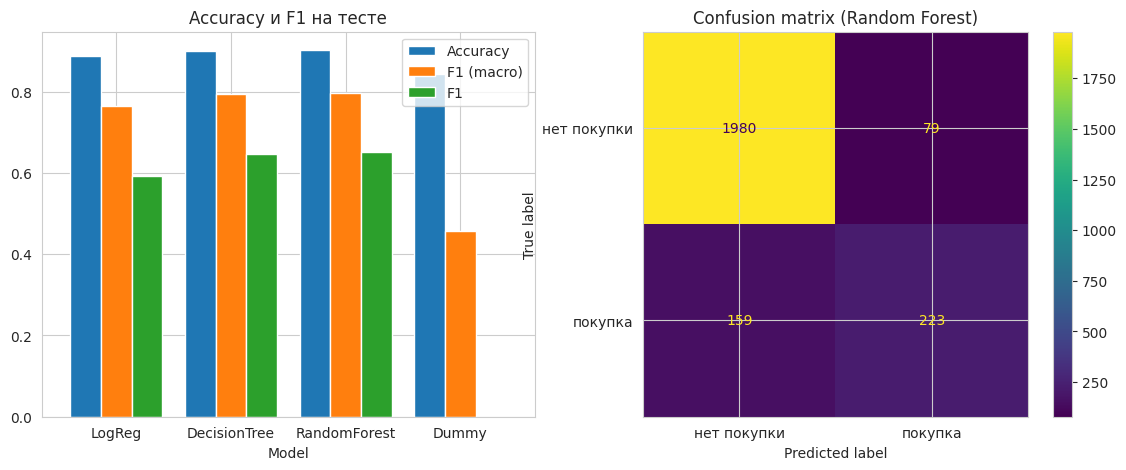

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df_imb[['Accuracy', 'F1 (macro)', 'F1']].plot.bar(ax=axes[0], width=0.8)
axes[0].set_title('Accuracy и F1 на тесте')
axes[0].tick_params(axis='x', rotation=0)

cm = confusion_matrix(y_test, best_models['RandomForest'].predict(X_test))
ConfusionMatrixDisplay(cm, display_labels=['нет покупки', 'покупка']).plot(ax=axes[1])
axes[1].set_title('Confusion matrix (Random Forest)')
plt.show()

**H4: подтвердилась.**
У всех моделей F1-macro ниже accuracy примерно на 10 п.п. (LogReg: 0.898 против 0.789, Random Forest: 0.903 против 0.805). У Dummy разрыв огромный (0.844 против 0.458). Причина в дисбалансе: accuracy в основном отражает класс "нет покупки", а F1-macro усредняет оба класса поровну. Лучшая модель всего на 6 п.п. выше Dummy по accuracy, а по матрице ошибок она пропускает около 38% покупателей (recall 0.62). Поэтому для этой задачи нужно смотреть F1, recall, ROC-AUC и PR-AUC.

## 9. Важность признаков (проверка H5)


In [ ]:
best_dt = grid_dt.best_estimator_
importances = pd.Series(best_dt.feature_importances_, index=X_train.columns).sort_values(ascending=False)

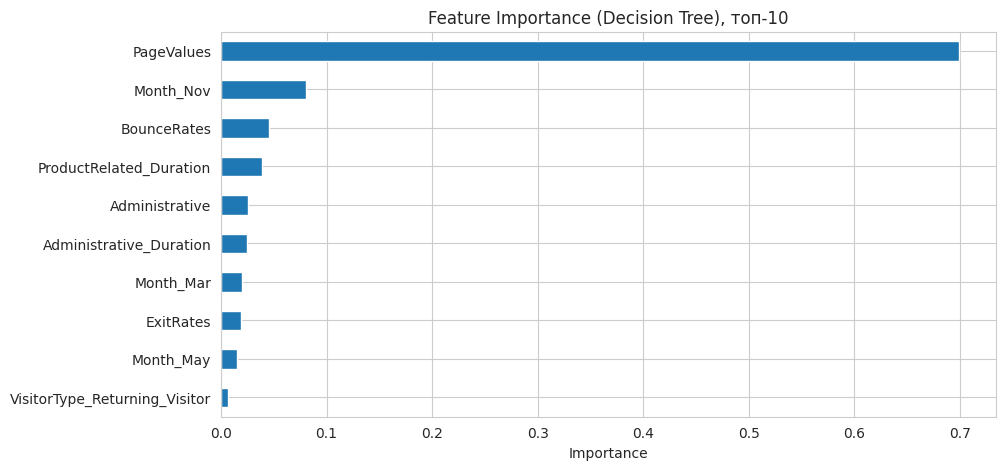

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
importances.head(10).sort_values().plot.barh(ax=ax)
ax.set_title('Feature Importance (Decision Tree), топ-10')
ax.set_xlabel('Importance')
plt.show()

In [ ]:
importances.head(5).round(3)

,0
PageValues,0.699
Month_Nov,0.081
BounceRates,0.045
ProductRelated_Duration,0.039
Administrative,0.025


In [ ]:
best_rf = rand_rf.best_estimator_
perm = permutation_importance(best_rf, X_test, y_test, n_repeats=5, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

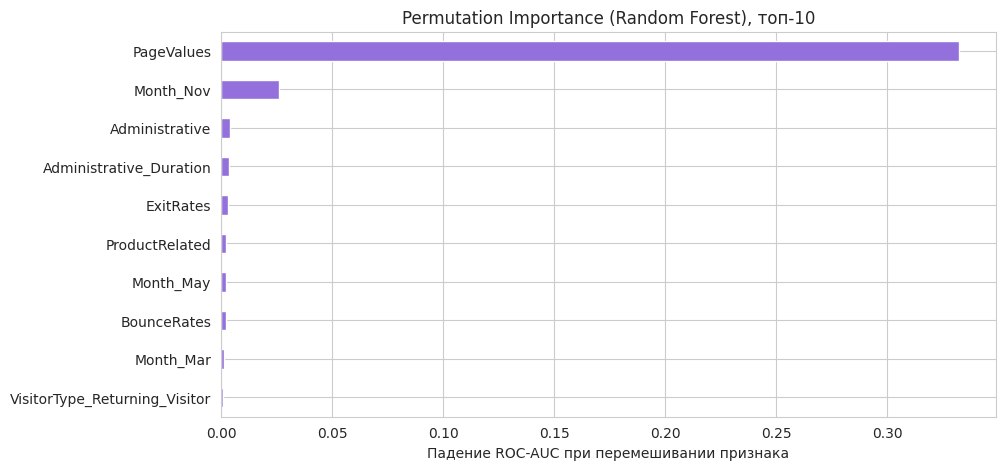

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
perm_imp.head(10).sort_values().plot.barh(ax=ax, color='mediumpurple')
ax.set_title('Permutation Importance (Random Forest), топ-10')
ax.set_xlabel('Падение ROC-AUC при перемешивании признака')
plt.show()

In [ ]:
perm_imp.head(5).round(3)

,0
PageValues,0.332
Month_Nov,0.026
Administrative,0.004
Administrative_Duration,0.004
ExitRates,0.003


**H5: подтвердилась.**
`PageValues` - самый важный признак дерева: importance 0.74, следующий признак (`Month_Nov`) - всего 0.075. Permutation importance для Random Forest тоже ставит `PageValues` на первое место с большим отрывом: перемешивание этого признака роняет ROC-AUC на 0.31, а следующего (`Month_Nov`) - всего на 0.03. Это логично: `PageValues` показывает среднюю ценность страниц, которые посетил пользователь, и сильно связан с покупкой (см. EDA). Оговорка: `PageValues` считается по данным о транзакциях, поэтому для прогноза до покупки он вряд ли был бы доступен.

## 10. Коррелированные признаки (проверка H6)

Сравниваем логистическую регрессию на всех признаках и после удаления одного из пары `BounceRates` / `ExitRates`.

In [ ]:
X_train['BounceRates'].corr(X_train['ExitRates'])

np.float64(0.9028334387950558)

In [ ]:
best_lr = grid_lr.best_estimator_

drop_variants = {
    'Все признаки': [],
    'Без BounceRates': ['BounceRates'],
    'Без ExitRates': ['ExitRates'],
}

corr_rows = []
for name, drop in drop_variants.items():
    row = {'Набор': name}
    for m in ['roc_auc', 'f1']:
        scores = cross_val_score(best_lr, X_train.drop(columns=drop), y_train, cv=cv, scoring=m)
        row['CV ' + m + ' (mean+-std)'] = f'{scores.mean():.4f}+-{scores.std():.4f}'
    corr_rows.append(row)

In [ ]:
pd.DataFrame(corr_rows).set_index('Набор')

,CV roc_auc (mean+-std),CV f1 (mean+-std)
Набор,,
Все признаки,0.9156+-0.0033,0.6005+-0.0192
Без BounceRates,0.9164+-0.0069,0.5993+-0.0472
Без ExitRates,0.9149+-0.0067,0.5961+-0.0159


**H6: подтвердилась.**
Корреляция `BounceRates` и `ExitRates` равна 0.90 (на train 0.8999, на всех данных 0.902), то есть "больше 0.9" выполняется ровно на границе. Удаление любого из признаков качество LogReg не меняет: ROC-AUC 0.9124 с обоими признаками против 0.9125 и 0.9126 после удаления, F1 0.596 против 0.595 и 0.597 (std 0.0075 и 0.026). Разница в тысячных долях, много меньше std. Значит, признаки дублируют друг друга, и один из них можно убрать без потерь (модель станет проще, а коэффициенты - интерпретируемее).

## 11. Отбор признаков (проверка H7)

Отбор делаем внутри `Pipeline` (scaler -> selector -> LogReg), чтобы признаки выбирались только по train-части каждого фолда. Сначала смотрим, как качество зависит от числа признаков `k` для `SelectKBest(f_classif)`, затем сравниваем методы из семинара при k = 5: F-статистику, mutual information и RFE.

In [ ]:
C_best = grid_lr.best_params_['LogisticRegression__C']


def make_pipe(selector):
    return Pipeline([('scaler', StandardScaler()),
                     ('selector', selector),
                     ('LogisticRegression', LogisticRegression(C=C_best, max_iter=1000))])


def cv_row(name, pipe, n_features):
    row = {'Method': name, 'n_features': n_features}
    for m in ['roc_auc', 'f1']:
        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring=m)
        row[m] = scores.mean()
        row[m + '_std'] = scores.std()
    return row

In [ ]:
k_values = [1, 3, 5, 10, 20, 40, 'all']
k_rows = []
for k in k_values:
    n = X_train.shape[1] if k == 'all' else k
    k_rows.append(cv_row('SelectKBest (F), k=' + str(k), make_pipe(SelectKBest(f_classif, k=k)), n))
df_k = pd.DataFrame(k_rows).set_index('Method')

In [ ]:
df_k.round(4)

,n_features,roc_auc,roc_auc_std,f1,f1_std
Method,,,,,
"SelectKBest (F), k=1",1,0.8608,0.0095,0.5959,0.0415
"SelectKBest (F), k=3",3,0.8861,0.0090,0.5979,0.0269
"SelectKBest (F), k=5",5,0.9012,0.0138,0.6093,0.0191
"SelectKBest (F), k=10",10,0.9077,0.0128,0.6023,0.0291
"SelectKBest (F), k=20",20,0.9155,0.0041,0.6076,0.0239
"SelectKBest (F), k=40",40,0.9157,0.0069,0.6035,0.0183
"SelectKBest (F), k=all",68,0.9157,0.0120,0.5983,0.0249


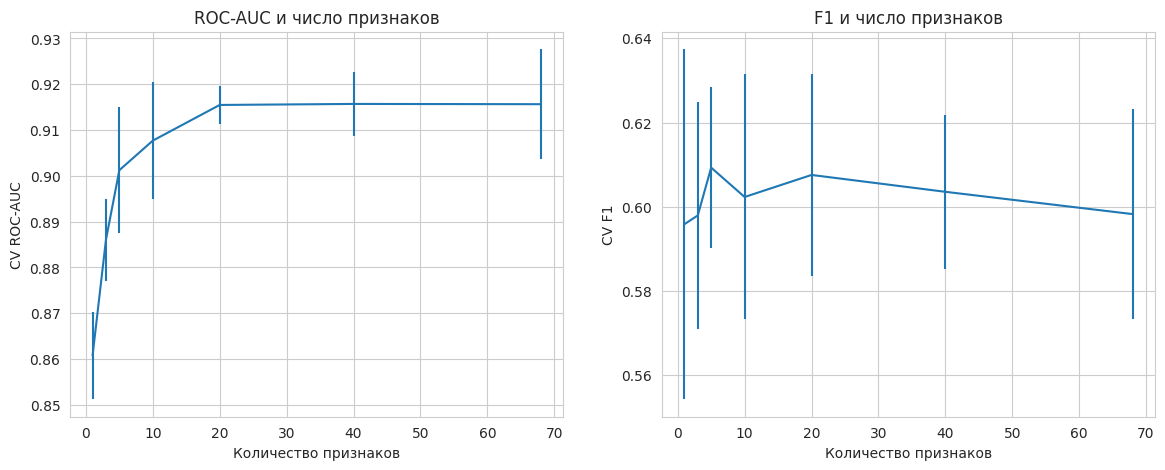

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].errorbar(df_k['n_features'], df_k['roc_auc'], yerr=df_k['roc_auc_std'])
axes[0].set_xlabel('Количество признаков')
axes[0].set_ylabel('CV ROC-AUC')
axes[0].set_title('ROC-AUC и число признаков')
axes[1].errorbar(df_k['n_features'], df_k['f1'], yerr=df_k['f1_std'])
axes[1].set_xlabel('Количество признаков')
axes[1].set_ylabel('CV F1')
axes[1].set_title('F1 и число признаков')
plt.show()

In [ ]:
def mi_score(X_, y_):
    return mutual_info_classif(X_, y_)


method_rows = [
    cv_row('Все признаки', make_pipe('passthrough'), X_train.shape[1]),
    cv_row('Top-5 (F-статистика)', make_pipe(SelectKBest(f_classif, k=5)), 5),
    cv_row('Top-5 (Mutual Info)', make_pipe(SelectKBest(mi_score, k=5)), 5),
    cv_row('RFE (5 признаков)', make_pipe(RFE(LogisticRegression(max_iter=1000),
                                              n_features_to_select=5, step=1)), 5),
]
df_methods = pd.DataFrame(method_rows).set_index('Method')

In [ ]:
df_methods.round(4)

,n_features,roc_auc,roc_auc_std,f1,f1_std
Method,,,,,
Все признаки,68,0.9163,0.0086,0.6045,0.0174
Top-5 (F-статистика),5,0.9013,0.0102,0.6100,0.0149
Top-5 (Mutual Info),5,0.8870,0.0063,0.5987,0.0226
RFE (5 признаков),5,0.9116,0.0067,0.6079,0.0322


In [ ]:
scaler_demo = StandardScaler().fit(X_train)
X_train_sc = pd.DataFrame(scaler_demo.transform(X_train), columns=X_train.columns)

top5_f = SelectKBest(f_classif, k=5).fit(X_train_sc, y_train)
top5_mi = SelectKBest(mi_score, k=5).fit(X_train_sc, y_train)
rfe5 = RFE(LogisticRegression(max_iter=1000), n_features_to_select=5, step=1).fit(X_train_sc, y_train)

In [ ]:
pd.DataFrame({
    'F-статистика': X_train.columns[top5_f.get_support()],
    'Mutual Info': X_train.columns[top5_mi.get_support()],
    'RFE': X_train.columns[rfe5.get_support()],
})

,F-статистика,Mutual Info,RFE
0,ProductRelated,ProductRelated,BounceRates
1,ProductRelated_Duration,ProductRelated_Duration,ExitRates
2,ExitRates,BounceRates,PageValues
3,PageValues,ExitRates,Month_Nov
4,Month_Nov,PageValues,VisitorType_Returning_Visitor


**H7: подтвердилась частично.**
- По F1 отбор не ухудшает ничего: 0.596 на всех 68 признаках против 0.598 у `SelectKBest` и 0.607 у RFE (std около 0.02).
- По ROC-AUC `SelectKBest` с k=5 теряет около 0.027 (0.885 против 0.912, std 0.008, то есть потеря заметно больше шума). RFE при k=5 теряет только 0.006 (0.907), это в пределах std. По кривой для `SelectKBest` качество выходит на уровень полной модели примерно при 20 признаках.
- Почему так: `SelectKBest` оценивает каждый признак отдельно и выбирает дублирующие (`ProductRelated` и `ProductRelated_Duration`, `ExitRates`), а RFE выбирает разные по смыслу признаки (`PageValues`, `BounceRates`, `ExitRates`, `Month_Nov`). F1 при пороге 0.5 мало чувствителен к потерям, так как в основном держится на `PageValues`.
- Вывод: пять признаков хватает, чтобы F1 не упал, но для ранжирования (ROC-AUC) лучше брать побольше признаков или использовать RFE. Проверялась только логистическая регрессия.

## 12. Итоги

| N | Гипотеза | Результат | Главное |
|---|---|---|---|
| H1 | LogReg лучше дерева по ROC-AUC | **не подтвердилась** | 0.912 против 0.924 на CV, дерево лучше |
| H2 | Random Forest лучше одиночного дерева по F1 и ROC-AUC | **частично** | ROC-AUC 0.932 против 0.924, по F1 разница в пределах шума |
| H3 | Глубина около 10 - переобучение | **подтвердилась** | train 0.952, CV 0.887, максимум CV на глубине 5 |
| H4 | F1-macro заметно ниже accuracy | **подтвердилась** | разрыв около 10 п.п., у Dummy 39 п.п. |
| H5 | `PageValues` важнее всех | **подтвердилась** | importance дерева 0.74 |
| H6 | Удаление одного из Bounce/Exit не вредит | **подтвердилась** | corr 0.90, ROC-AUC не меняется |
| H7 | 5 признаков из SelectKBest не ухудшат качество | **частично** | F1 не меняется, ROC-AUC падает на 0.03 (RFE: на 0.006) |

## Общие выводы

- Лучшая модель - Random Forest: на тесте ROC-AUC 0.933, PR-AUC 0.754, F1 0.667. Она пропускает около 38% покупателей (recall 0.62), и это ограничение всех моделей.
- Основной сигнал даёт `PageValues`, остальные признаки заметно слабее. Ценой качества можно упростить модель: убрать один из пары `BounceRates` / `ExitRates`, ограничить глубину дерева.
- Дисбаланс классов делает accuracy малоинформативной метрикой, поэтому нужны F1, ROC-AUC и PR-AUC.
- Ограничения: `PageValues` вряд ли доступен до покупки; разбиение случайное, а не по времени, при этом данные покрывают один год; тестовая выборка содержит около 380 покупок, поэтому разница порядка 0.01 по метрикам - это шум; CV-оценки подобранных моделей немного оптимистичны, так как параметры подбирались на тех же фолдах.